# M08 · Comparación de modelos y elección del mejor

En las fases anteriores entrenamos 6 modelos para predecir el grupo NOVA (1 a 4) de un producto:
regresión logística (M01), KNN (M02), Random Forest (M03), XGBoost (M05), LightGBM (M06) y árbol de decisión (M09).

**Objetivo de este notebook:**
1. Comparar los 6 modelos con **la misma métrica**.
2. Elegir el mejor y justificar la decisión.
3. Entrenar el modelo final y guardarlo con `joblib` (lo usará la app Streamlit).
4. Evaluarlo **una sola vez** sobre el test y guardar su matriz de confusión.

**Criterio de comparación:** usamos solo los resultados de **validación cruzada (CV, 5 folds por grupos)**,
porque es la única métrica que tienen los 6 modelos con el mismo método.
No usamos el F1 en test que M05 y M06 guardaron: el test debe quedar intacto hasta el Paso 5 de este notebook.

## Paso 1 · Cargar las métricas de los 6 modelos

Cada modelo guardó sus resultados en `results/Mxx-metrics.json`.
Leemos los 6 ficheros y nos quedamos con el bloque `cv`, que contiene el F1 macro, su desviación,
el *gap* (diferencia entre el F1 de train y el de validación, mide el sobreajuste) y el recall por clase.

In [1]:
import sys
sys.path.insert(0, "..")

import json
import pandas as pd
from src.modeling import ROOT

RESULTS = ROOT / "results"
files = sorted(f for f in RESULTS.glob("M0*-metrics.json") if f.name != "M08-metrics.json")
[f.name for f in files]


['M01-metrics.json',
 'M02-metrics.json',
 'M03-metrics.json',
 'M05-metrics.json',
 'M06-metrics.json',
 'M09-metrics.json']

## Paso 2 · Tabla comparativa

Construimos una tabla con una fila por modelo. Columnas:
- `f1_macro_cv`: F1 macro medio en validación cruzada (más alto = mejor).
- `f1_macro_cv_std`: desviación entre folds (más bajo = más estable).
- `gap`: F1 train − F1 validación (más bajo = menos sobreajuste).
- `recall_nova_X`: porcentaje de productos de cada clase que el modelo encuentra.

Ordenamos de mejor a peor F1.

In [2]:
rows = []
for f in files:
    with open(f) as fh:
        d = json.load(fh)
    cv = d["cv"]
    rows.append({
        "modelo": d["model"],
        "f1_macro_cv": cv["f1_macro_cv"],
        "f1_macro_cv_std": cv["f1_macro_cv_std"],
        "gap": cv["gap"],
        **{f"recall_{k}": v for k, v in cv["recall"].items()},
    })

comparison = pd.DataFrame(rows).sort_values("f1_macro_cv", ascending=False).reset_index(drop=True)
comparison  

,modelo,f1_macro_cv,f1_macro_cv_std,gap,recall_nova_1,recall_nova_2,recall_nova_3,recall_nova_4
0,"LightGBM (Optuna, prueba 49)",0.9650,0.0019,0.0346,0.9818,0.9921,0.9502,0.9616
1,"XGBoost (Optuna, prueba 96)",0.9646,0.0023,0.0269,0.9832,0.9916,0.9559,0.9583
2,RandomForestClassifier,0.9607,0.0025,0.0306,0.9849,0.9907,0.9554,0.9517
3,LogisticRegression,0.9508,0.0009,0.0014,0.9792,0.9872,0.9251,0.9495
4,DecisionTreeClassifier,0.9482,0.0019,0.0197,0.9798,0.9835,0.9353,0.9409
5,KNeighborsClassifier,0.9351,0.0036,0.0646,0.9536,0.9877,0.9102,0.9316


### 2.1 Resultados y análisis

**Cómo leer la tabla**
- **F1 macro:** nota única entre 0 y 1 que combina *recall* (cuántos productos de una clase encontramos) y *precisión*
  (cuántas veces acertamos al decir esa clase). "Macro" = media de las 4 clases con el mismo peso, así que la clase mayoritaria
  (NOVA 4, ~55 %) no puede tapar los fallos en las otras.
- **Recall por clase:** de todos los productos que realmente son NOVA X, el % que el modelo detecta.
- **Gap:** F1 en train − F1 en validación. Mide el sobreajuste (el modelo memoriza en vez de generalizar). Objetivo del equipo: < 0,05.
- **Std:** variación del F1 entre los 5 folds. Más bajo = resultado más estable.

**Qué vemos**
1. **Ranking por F1:** LightGBM (0,9650) ≈ XGBoost (0,9646) > Random Forest (0,9607) > Regresión logística (0,9508)
   > Árbol de decisión (0,9482) > KNN (0,9351).
2. **LightGBM y XGBoost están empatados.** La diferencia (0,0004) es mucho menor que la desviación entre folds (≈ 0,002):
   no podemos afirmar que uno sea mejor por F1.
3. **Sobreajuste:** XGBoost tiene el gap más bajo de los tres mejores (0,0269 frente a 0,0306 de Random Forest y 0,0346 de LightGBM).
   KNN (0,0646) es el único que supera el límite de 0,05. La regresión logística casi no sobreajusta (0,0014) pero rinde peor:
   es un modelo demasiado simple para capturar todo el patrón.
4. **Por clase:** NOVA 2 es fácil para todos (≈ 0,99). **NOVA 3 es la clase difícil** (0,91–0,96): se confunde con NOVA 4
   porque la frontera entre "procesado" y "ultraprocesado" es borrosa. XGBoost y Random Forest son los mejores en NOVA 3 (0,956);
   LightGBM es el mejor en NOVA 4 (0,962).
5. **Estabilidad:** la regresión logística es la más estable (std 0,0009); KNN la menos (0,0036). 

## Paso 3 · Elección del modelo

### 3.1 Criterios de decisión

Aplicamos los criterios en este orden:
1. **F1 macro en CV:** el modelo debe estar entre los mejores. Si dos modelos difieren menos que la desviación entre folds, los consideramos empatados.
2. **Gap train-validación (sobreajuste):** entre los empatados, preferimos el que generaliza mejor (gap más bajo, siempre < 0,05).
3. **Recall en NOVA 3:** es la clase más difícil y donde más se diferencian los modelos, así que desempata.

### 3.2 Aplicación

| Criterio | LightGBM | XGBoost | Random Forest |
|---|---|---|---|
| F1 macro CV | 0,9650 | 0,9646 | 0,9607 |
| Gap | 0,0346 | **0,0269** | 0,0306 |
| Recall NOVA 3 | 0,9502 | **0,9559** | 0,9554 |

- **Criterio 1:** LightGBM y XGBoost empatan (diferencia 0,0004, menor que la std ≈ 0,002). Random Forest queda 0,004 por debajo, una diferencia mayor que el ruido.
- **Criterio 2:** XGBoost sobreajusta menos (0,0269 frente a 0,0346). LightGBM casi memoriza el train (F1 train ≈ 0,9997).
- **Criterio 3:** XGBoost detecta mejor NOVA 3 (0,9559 frente a 0,9502).

### 3.3 Decisión

**Elegimos XGBoost (M05).** No es el de mayor F1 (LightGBM le gana por 0,0004, dentro del ruido), pero generaliza mejor y es el mejor
en la clase más difícil.

### 3.4 Limitaciones de la decisión
- LightGBM es mejor en NOVA 4 (0,9616 frente a 0,9583). Si la aplicación priorizara detectar ultraprocesados, la decisión podría cambiar.
- La elección se basa solo en validación cruzada. El test no se ha usado para elegir: solo para dar la nota final (Paso 5).

## Paso 4 · Entrenar el modelo final

**Qué hacemos:** entrenamos el XGBoost elegido con **todo el train**, usando exactamente las variables y los hiperparámetros
que guardó M05 en `results/M05-metrics.json` (los de la prueba 96 de Optuna).

**Por qué lo reentrenamos aquí y no reutilizamos el fichero de M05:** la carpeta `models/` no se sube a git (los `.joblib` pesan y
se pueden regenerar). Si una compañera clona el repositorio no tendría el modelo. Leyendo el JSON y reentrenando, cualquiera obtiene el mismo modelo con este notebook.
No buscamos hiperparámetros otra vez: ya están decididos.

### 4.1 Cargar datos, variables e hiperparámetros

In [3]:
from src.modeling import DATA_PATH, MODELS_DIR, LABELS

with open(RESULTS / "M05-metrics.json") as fh:
    m05 = json.load(fh)

features = m05["features"]
params = m05["params"]

df = pd.read_csv(DATA_PATH, dtype={"code": str})
train = df[df["split"] == "train"]
test = df[df["split"] == "test"]

print("train:", train.shape, "| test:", test.shape)
print("variables:", len(features))
params

train: (38495, 35) | test: (9624, 35)
variables: 26


{'objective': 'multi:softprob',
 'tree_method': 'hist',
 'enable_categorical': True,
 'random_state': 42,
 'n_jobs': -1,
 'n_estimators': 255,
 'learning_rate': 0.22240513290864158,
 'max_depth': 10,
 'min_child_weight': 3,
 'gamma': 0.24070270214386436,
 'subsample': 0.86366572941564,
 'colsample_bytree': 0.5460632689060315,
 'reg_lambda': 0.5938267535387278,
 'reg_alpha': 0.1628792046230102}

### Resultados
Hay 38.495 productos de train y 9.624 de test, con 26 variables (la misma lista que usó M05). Los hiperparámetros son los de la prueba 96 de Optuna:
255 árboles de profundidad máxima 10 y tasa de aprendizaje 0,22.

### 4.2 Entrenar

Pasos (los mismos que en M05):
- `pnns_groups_2` se convierte a tipo `category`: así XGBoost la trata como categoría y no como un número.
- `nova_group − 1`: XGBoost necesita las clases como 0, 1, 2, 3 (NOVA 1-4 menos 1). Al predecir sumaremos 1.
- **Pesos por producto** (`balanced`): los productos de las clases pequeñas (NOVA 2) pesan más para que el modelo no ignore a la clase mayoritaria.

In [4]:
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

X_train = train[features].copy()
X_train["pnns_groups_2"] = X_train["pnns_groups_2"].astype("category")
y_train = train["nova_group"] - 1
sample_weight = compute_sample_weight("balanced", y_train)

model = XGBClassifier(**params)
model.fit(X_train, y_train, sample_weight=sample_weight)

print("modelo entrenado con", model.n_estimators, "árboles y", X_train.shape[0], "productos")

modelo entrenado con 255 árboles y 38495 productos


### Resultados
El modelo se entrena con los 38.495 productos de train y 255 árboles. Es el mismo modelo que M05 (mismas variables, hiperparámetros y semilla `random_state=42`).

## Paso 5 · Nota final en el test

**Qué hacemos:** medimos el modelo con el 20 % de productos que nunca se usó para entrenar ni para elegir hiperparámetros.

**Importante:** M05 ya calculó una vez el F1 en test (0,9611) para comprobar que no había sobreajuste. Aquí repetimos el cálculo con el modelo
reentrenado y lo guardamos como nota oficial. El test **no se ha usado para decidir** nada (los hiperparámetros y la elección del modelo salen de la validación cruzada), por lo que sigue siendo una estimación honesta.

A `pnns_groups_2` del test le damos **las categorías del train**, para que el modelo interprete cada categoría igual que al entrenar.

In [5]:
from sklearn.metrics import classification_report, f1_score

X_test = test[features].copy()
X_test["pnns_groups_2"] = pd.Categorical(
    X_test["pnns_groups_2"], categories=X_train["pnns_groups_2"].cat.categories
)
y_test = test["nova_group"]

y_pred = model.predict(X_test) + 1
f1_test = f1_score(y_test, y_pred, average="macro")

print(f"macro F1 test: {f1_test:.4f}  (M05 guardó {m05['test']['macro_f1']})\n")
print(classification_report(y_test, y_pred, labels=LABELS, digits=3))

macro F1 test: 0.9611  (M05 guardó 0.9611)

              precision    recall  f1-score   support

           1      0.941     0.978     0.959      1238
           2      0.992     0.990     0.991      1077
           3      0.900     0.944     0.921      1966
           4      0.987     0.960     0.973      5343

    accuracy                          0.962      9624
   macro avg      0.955     0.968     0.961      9624
weighted avg      0.964     0.962     0.963      9624



### Resultados
**Macro F1 en test: 0,9611**, igual que el valor guardado por M05 (y cerca del 0,9646 de la validación cruzada): el modelo generaliza y no hay señales de sobreajuste.

Por clase:
- **NOVA 2 es la mejor** (recall 0,990, precisión 0,992): aceites, azúcar y vinagres se reconocen fácilmente.
- **NOVA 3 es la más débil** en precisión (0,900): el modelo a veces llama "procesado" a productos que son ultraprocesados.
- **NOVA 4** tiene el recall más bajo de las grandes (0,960): algunos ultraprocesados se le escapan.

## Paso 6 · Matriz de confusión

Cada **fila** es la clase real y cada **columna** la clase que predijo el modelo. La diagonal son los aciertos; fuera de la diagonal
vemos qué clases se confunden.
- A la izquierda: número de productos.
- A la derecha: porcentaje de cada clase real (la diagonal es el *recall*).

Guardamos la imagen en `results/M08-confusion_matrix.png`.

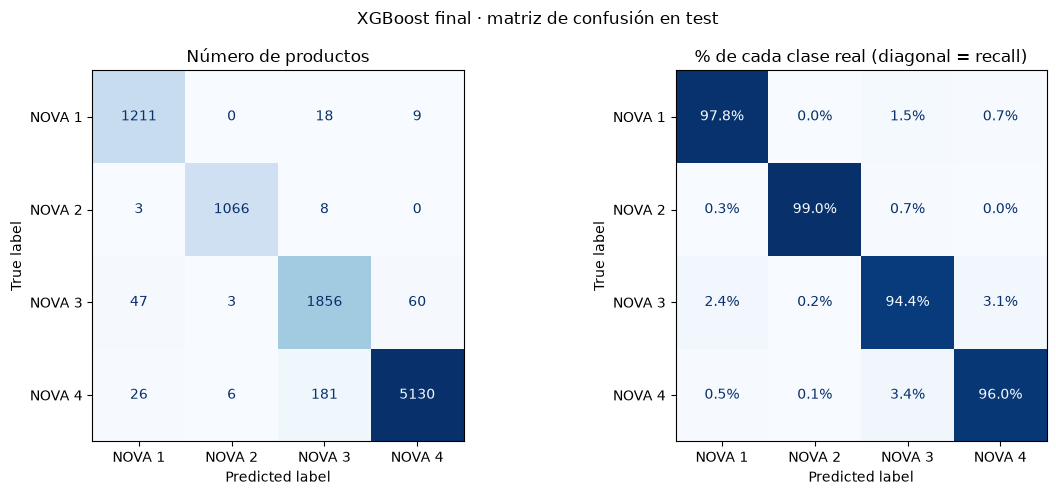

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=LABELS)
cm_pct = confusion_matrix(y_test, y_pred, labels=LABELS, normalize="true")
nombres = [f"NOVA {k}" for k in LABELS]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(cm, display_labels=nombres).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Número de productos")
ConfusionMatrixDisplay(cm_pct, display_labels=nombres).plot(
    ax=axes[1], cmap="Blues", colorbar=False, values_format=".1%"
)
axes[1].set_title("% de cada clase real (diagonal = recall)")
fig.suptitle("XGBoost final · matriz de confusión en test")
fig.tight_layout()
fig.savefig(RESULTS / "M08-confusion_matrix.png", dpi=150)
plt.show()

### Resultados
El modelo acierta 9.263 de 9.624 productos y se equivoca en **361 (3,8 %)**.

- **El error principal es NOVA 4 → NOVA 3:** 181 ultraprocesados clasificados como procesados. Son la mitad de todos los errores (181 de 361).
  El error contrario (NOVA 3 → NOVA 4) es mucho menor: 60.
- NOVA 3 también se confunde con NOVA 1 (47 productos): alimentos casi naturales a los que se añade sal o aceite.
- NOVA 2 casi no falla (11 errores de 1.077): coincide con lo que vimos en el EDA.

La matriz confirma que toda la dificultad está en la **frontera entre procesado (3) y ultraprocesado (4)**.

## Paso 7 · Guardar el modelo y las métricas

Guardamos dos cosas:
1. **`models/m08_xgboost.joblib`** (no va a git): lo que cargará la app Streamlit. Es un diccionario con el modelo y lo necesario para usarlo:
   la lista de variables, las categorías de `pnns_groups_2` y el desplazamiento de etiquetas (`label_offset = 1`, porque el modelo predice 0-3 y NOVA es 1-4). Es el mismo formato que M05 y M06.
2. **`results/M08-metrics.json`** (sí va a git): tabla de comparación, nota en test, recall por clase y la matriz de confusión.

In [7]:
import platform
import joblib
import sklearn
import xgboost
from sklearn.metrics import recall_score

MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(
    {
        "model": model,
        "features": features,
        "pnns_categories": list(X_train["pnns_groups_2"].cat.categories),
        "label_offset": 1,
    },
    MODELS_DIR / "m08_xgboost.joblib",
)

recalls = recall_score(y_test, y_pred, labels=LABELS, average=None)
metrics = {
    "model": "XGBoost (Optuna, prueba 96) - modelo final elegido en M08",
    "params": params,
    "features": features,
    "comparison_cv": comparison.round(4).to_dict(orient="records"),
    "test": {
        "macro_f1": round(float(f1_test), 4),
        "recall": {f"nova_{k}": round(float(r), 4) for k, r in zip(LABELS, recalls)},
        "confusion_matrix": cm.tolist(),
    },
    "n_train": len(train),
    "n_test": len(test),
    "env": {
        "python": platform.python_version(),
        "scikit-learn": sklearn.__version__,
        "xgboost": xgboost.__version__,
    },
}
(RESULTS / "M08-metrics.json").write_text(json.dumps(metrics, indent=2))
print("guardado:", MODELS_DIR / "m08_xgboost.joblib")
print("guardado:", RESULTS / "M08-metrics.json")

guardado: /app/models/m08_xgboost.joblib
guardado: /app/results/M08-metrics.json


### Resultados
Se han creado `models/m08_xgboost.joblib` (2,3 MB, ignorado por git) y `results/M08-metrics.json`. La imagen de la matriz está en `results/M08-confusion_matrix.png`.

## Paso 8 · Comprobar que el fichero guardado funciona

Un modelo guardado que no se puede volver a cargar no sirve. Lo cargamos desde el disco, **como lo hará la app**, preparamos el test solo con lo que contiene
el fichero (variables y categorías) y comprobamos que las predicciones son idénticas a las del Paso 5.

In [8]:
saved = joblib.load(MODELS_DIR / "m08_xgboost.joblib")

X_check = test[saved["features"]].copy()
X_check["pnns_groups_2"] = pd.Categorical(
    X_check["pnns_groups_2"], categories=saved["pnns_categories"]
)
y_check = saved["model"].predict(X_check) + saved["label_offset"]

assert (y_check == y_pred).all()
print("predicciones idénticas a las del Paso 5:", bool((y_check == y_pred).all()))

predicciones idénticas a las del Paso 5: True


### Resultados
Las predicciones del modelo cargado desde el disco son **idénticas** a las del modelo en memoria. El fichero `.joblib` es válido y la app Streamlit puede cargarlo con:

```python
saved = joblib.load("models/m08_xgboost.joblib")

nova = saved["model"].predict(X) + saved["label_offset"]
```

## Paso 9 · Conclusiones y limitaciones

### 9.1 Resumen
- Comparamos 6 modelos con la misma métrica (validación cruzada, 5 folds). Los de boosting (XGBoost, LightGBM) y Random Forest son los mejores (F1 macro 0,961-0,965).
- Elegimos **XGBoost**: está empatado en F1 con LightGBM, pero sobreajusta menos (gap 0,027) y detecta mejor NOVA 3.
- Nota final en test: **F1 macro 0,9611**, con el modelo entrenado solo con el train. Recall por clase: NOVA 1 0,978 · NOVA 2 0,990 · NOVA 3 0,944 · NOVA 4 0,960.
- Entregables: `models/m08_xgboost.joblib` (para la app), `results/M08-metrics.json` y `results/M08-confusion_matrix.png`.

### 9.2 Limitación principal: el objetivo y las variables vienen de lo mismo
Open Food Facts asigna NOVA en parte con reglas basadas en los ingredientes y aditivos de la etiqueta, y esas mismas informaciones son las variables
con las que entrenamos (`n_ingredientes`, `additives_n`, marcadores `tiene_*`). Ya lo advertimos en el EDA (Paso 7 y sección 14.3).

**Consecuencia:** el F1 alto (~0,96) mide en parte lo bien que el modelo reproduce las reglas de Open Food Facts, no lo bien que distingue un ultraprocesado
según un criterio experto independiente. No podemos afirmar que 0,96 sea la precisión "real" frente a la verdad nutricional.

**Lo que ya hemos comprobado (en M05):**
- **Sin ninguna variable de ingredientes**, el F1 macro de validación baja de 0,964 a **0,862**. Con solo la categoría y los nutrientes, el modelo no se hunde: no se limita a copiar la regla. Pero las variables de ingredientes aportan unos 10 puntos.
- Esa pérdida se concentra en **NOVA 3** (recall 0,723 sin ingredientes): los ingredientes sirven sobre todo para separar procesado de ultraprocesado.
- Con las **etiquetas mezcladas** el F1 es 0,246 (azar con 4 clases): la validación no tiene fugas, el 0,96 viene de una relación real.
- `sin_lista_ingredientes` es un atajo parcial (ningún NOVA 3 o 4 carece de lista), pero quitarla solo cambia el F1 de 0,964 a 0,963.

### 9.3 Cómo se podría resolver o medir mejor

| Propuesta | Qué aporta | Esfuerzo |
|---|---|---|
| **Validación externa:** que una persona experta etiquete a mano una muestra pequeña y compararla con el modelo | Única forma de medir la precisión frente a un criterio independiente de Open Food Facts | Medio |
| **Probar con etiquetas reales:** en la app los ingredientes los extrae Gemini de una foto; comprobar el modelo con esas extracciones | Detecta la pérdida de calidad entre el dataset limpio y la app | Medio |
| **Variables menos dependientes de las reglas de OFF:** representar el texto de ingredientes con TF-IDF o embeddings en lugar de marcadores manuales | El modelo podría aprender patrones que las reglas no recogen (y manejar listas en varios idiomas, un fallo visto en M05) | Alto |
| **Mostrar la confianza en la app:** enseñar la probabilidad de cada clase y avisar cuando sea baja | Evita presentar como cierta una estimación dudosa, sobre todo en la frontera NOVA 3/4 | Bajo |
| **Presentar el resultado como estimación** "según el criterio de Open Food Facts" | Honestidad frente al usuario | Bajo |

### 9.4 Otras limitaciones
- El modelo solo sirve para productos con tabla nutricional y vendidos en España (el test sale del mismo conjunto de Open Food Facts).
- El error principal es NOVA 4 clasificado como NOVA 3 (181 de 361 errores). Algunas etiquetas de Open Food Facts son discutibles, así que parte de ese error es ruido del objetivo.
- Solo se comparó el modelo con CV. Una comparación con explicabilidad completa (SHAP) queda como trabajo futuro.